# Netflix catalog analysis

What is on Netflix, where it comes from, and how the catalog changed between 2015 and 2021.

The data is the public Netflix Movies and TV Shows dataset (8,807 titles, scraped up to 25 September 2021). `src/clean.py` cleans it and writes three tables, which this notebook and the Power BI dashboard both read:

- `titles.csv`: one row per title
- `title_genres.csv`: one row per title and genre (a title has 2.2 genres on average)
- `title_countries.csv`: one row per title and production country

Run `python src/clean.py` before this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
CLEAN = ROOT / "data" / "clean"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

titles = pd.read_csv(CLEAN / "titles.csv", parse_dates=["date_added"])
genres = pd.read_csv(CLEAN / "title_genres.csv")
countries = pd.read_csv(CLEAN / "title_countries.csv")

MOVIE, TV, MUTED, GRID = "#2F5D8A", "#D9822B", "#6B7280", "#E5E7EB"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": "#1F2937", "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})

def save(fig, name):
    fig.savefig(IMAGES / name)

print(f"{len(titles):,} titles, {len(genres):,} title-genre rows, {len(countries):,} title-country rows")
print(f"date_added runs from {titles['date_added'].min():%d %b %Y} to {titles['date_added'].max():%d %b %Y}")

8,807 titles, 19,323 title-genre rows, 10,012 title-country rows
date_added runs from 01 Jan 2008 to 25 Sep 2021


## Data checks

The cleaning script fixed these problems in the raw file. They are worth knowing because each would quietly distort a chart:

- **Shifted values:** three Louis C.K. specials had their running time ("74 min") in the rating column and no duration.
- **Whitespace:** 88 dates had a leading space, which stops them parsing as dates.
- **Stray commas:** 7 country lists had leading or trailing commas, which would create blank countries.
- **Missing values:** director (2,634), cast (825) and country (831) are filled with "Unknown" so they still count in totals. The 10 missing `date_added` values stay blank rather than being guessed.
- **TV release year:** for TV shows, `release_year` is the latest season, so the release-to-Netflix gap is only calculated for movies.

In [2]:
checks = pd.Series({
    "Titles": len(titles),
    "Unique show_id": titles["show_id"].nunique(),
    "Missing date_added": titles["date_added"].isna().sum(),
    "Country unknown": (titles["country"] == "Unknown").sum(),
    "Rating unknown": (titles["rating"] == "Unknown").sum(),
    "Movies without a duration": titles.loc[titles["type"] == "Movie", "duration_min"].isna().sum(),
})
checks.to_frame("count")

,count
Titles,8807
Unique show_id,8807
Missing date_added,10
Country unknown,831
Rating unknown,7
Movies without a duration,0


## Movies and TV shows

Movies are 70% of the catalog: 6,131 movies against 2,676 TV shows.

In [3]:
titles["type"].value_counts().to_frame("titles").assign(share=lambda d: (d["titles"] / d["titles"].sum()).map("{:.1%}".format))

,titles,share
type,,
Movie,6131,69.6%
TV Show,2676,30.4%


## How fast the catalog grew

Additions grew almost fivefold from 2016 to 2019 (429 to 2,016 titles a year), then dipped in 2020. 2021 stops at 25 September, so its lower total is a partial year and not a decline. TV's share of additions fell from 41% in 2016 to 25% in 2018 as the movie library expanded, then climbed back to 34% by 2021.

type,Movie,TV Show,total,tv_share
year_added,,,,
2015,56,26,82,32%
2016,253,176,429,41%
2017,839,349,1188,29%
2018,1237,412,1649,25%
2019,1424,592,2016,29%
2020,1284,595,1879,32%
2021,993,505,1498,34%


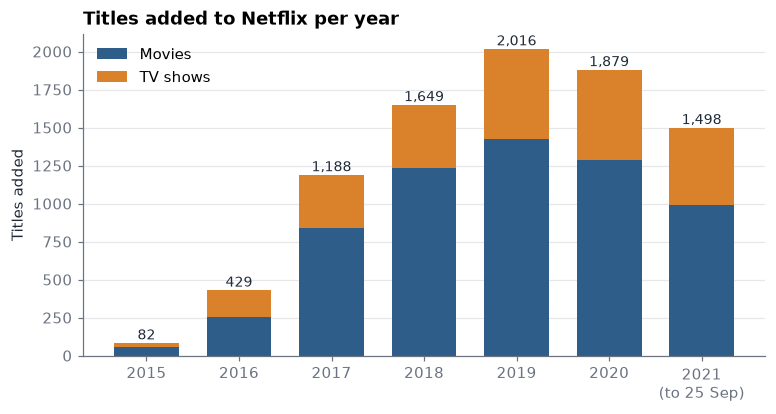

In [4]:
added = (titles.dropna(subset=["year_added"])
         .query("year_added >= 2015")
         .groupby(["year_added", "type"]).size().unstack())
added.index = added.index.astype(int)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(added.index, added["Movie"], color=MOVIE, label="Movies", width=0.7)
ax.bar(added.index, added["TV Show"], bottom=added["Movie"], color=TV, label="TV shows", width=0.7)
for year, total in added.sum(axis=1).items():
    ax.text(year, total + 25, f"{total:,}", ha="center", fontsize=9, color="#1F2937")
ax.set_title("Titles added to Netflix per year")
ax.set_ylabel("Titles added")
ax.set_xticks(added.index, [str(y) if y < 2021 else "2021\n(to 25 Sep)" for y in added.index])
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False)
save(fig, "added_by_year.png")
added.assign(total=added.sum(axis=1), tv_share=lambda d: (d["TV Show"] / d["total"]).map("{:.0%}".format))

## How recent the content is

Two different questions get mixed up here, so I keep them apart:

- **When was a title added to Netflix?** 98.4% of titles with a date were added in 2016 or later. That mostly says the dataset was scraped from the catalog as it stood in 2021.
- **When was a title released?** 64.2% of titles were released in 2016 or later. This is the more useful number: almost two thirds of the catalog is recent content, with a long tail of older films.

Added to Netflix in 2016 or later: 98.4% of 8,797 titles with a date
Released in 2016 or later:         64.2% of 8,807 titles


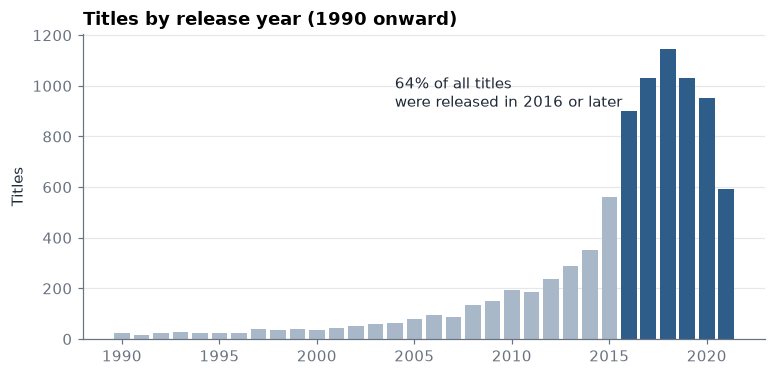

In [5]:
has_date = titles["year_added"].notna()
added_recent = (titles.loc[has_date, "year_added"] >= 2016).mean()
released_recent = (titles["release_year"] >= 2016).mean()
print(f"Added to Netflix in 2016 or later: {added_recent:.1%} of {has_date.sum():,} titles with a date")
print(f"Released in 2016 or later:         {released_recent:.1%} of {len(titles):,} titles")

released = titles.loc[titles["release_year"] >= 1990, "release_year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(released.index, released.values, color=[MOVIE if y >= 2016 else "#A9B8C9" for y in released.index], width=0.8)
ax.set_title("Titles by release year (1990 onward)")
ax.set_ylabel("Titles")
ax.text(2004, released.max() * 0.8, f"{released_recent:.0%} of all titles\nwere released in 2016 or later",
        color="#1F2937", fontsize=10)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
save(fig, "release_years.png")

## Where the content comes from

The US is involved in 3,690 titles, 46% of the titles with a known country. India is a clear second with 1,046, ahead of the UK. Co-productions count once for each country (1,315 titles have more than one), so these counts add up to more than the number of titles. 9.4% of titles have no country listed.

,titles
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


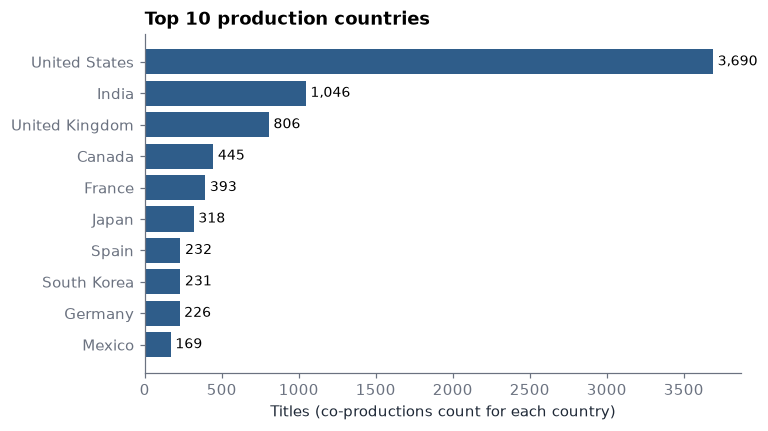

In [6]:
top_countries = countries["country"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top_countries.index, top_countries.values, color=MOVIE)
for i, v in enumerate(top_countries.values):
    ax.text(v + 30, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 10 production countries")
ax.set_xlabel("Titles (co-productions count for each country)")
save(fig, "top_countries.png")
countries["country"].value_counts().head(10).to_frame("titles")

## Genres

"International Movies" is the largest genre label, with 2,752 titles, then Dramas and Comedies. Netflix files a title under up to three genres, so this is a count of labels, not of titles.

,titles
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


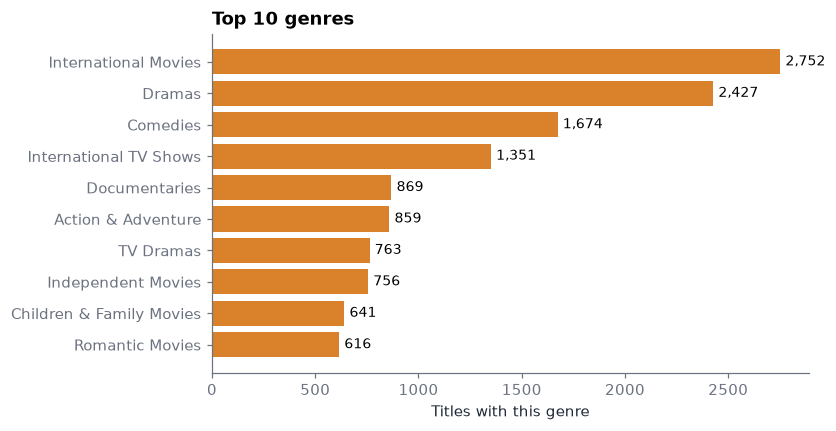

In [7]:
top_genres = genres["genre"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top_genres.index, top_genres.values, color=TV)
for i, v in enumerate(top_genres.values):
    ax.text(v + 25, i, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 10 genres")
ax.set_xlabel("Titles with this genre")
save(fig, "top_genres.png")
genres["genre"].value_counts().head(10).to_frame("titles")

## Who the catalog is for

I grouped the TV and film ratings into four audiences (TV-MA, R and NC-17 as Adults; TV-14, PG-13, TV-PG and PG as Teens; the TV-Y, TV-G and G ratings as Kids; NR and UR as Unrated). Adult content is the largest group for both movies and TV. TV has more than twice the share of kids' content (17.4% against 7.2%).

audience,Adults,Teens,Kids,Unrated
type,,,,
Movie,46.7,44.8,7.2,1.4
TV Show,42.9,39.5,17.4,0.3


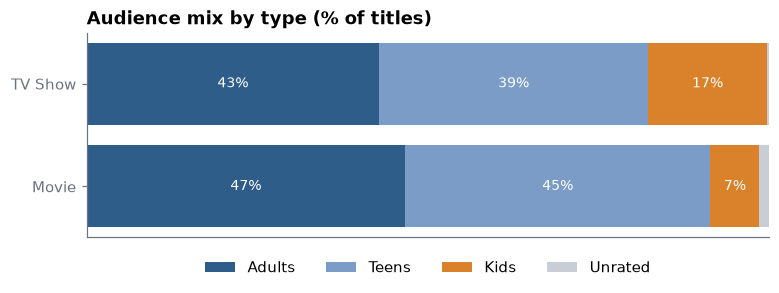

In [8]:
audience = (pd.crosstab(titles["type"], titles["audience"], normalize="index") * 100)[["Adults", "Teens", "Kids", "Unrated"]]
fig, ax = plt.subplots(figsize=(8, 2.4))
left = pd.Series(0.0, index=audience.index)
for col, color in zip(audience.columns, [MOVIE, "#7A9CC6", TV, "#C9CED6"]):
    ax.barh(audience.index, audience[col], left=left, color=color, label=col)
    for i, (v, l) in enumerate(zip(audience[col], left)):
        if v >= 5:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += audience[col]
ax.set_title("Audience mix by type (% of titles)")
ax.set_xlim(0, 100); ax.set_xticks([])
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.05))
save(fig, "audience.png")
audience.round(1)

## How long movies take to reach Netflix

Half of all movies arrive within 2 years of release, and 30% arrive the same year they come out. About one in five is 10 or more years old when added, most likely older films licensed from studios. The data has no flag for Netflix originals, so I can't split the two directly.

Median: 2 years
Same year: 30.4%
10+ years: 19.4%


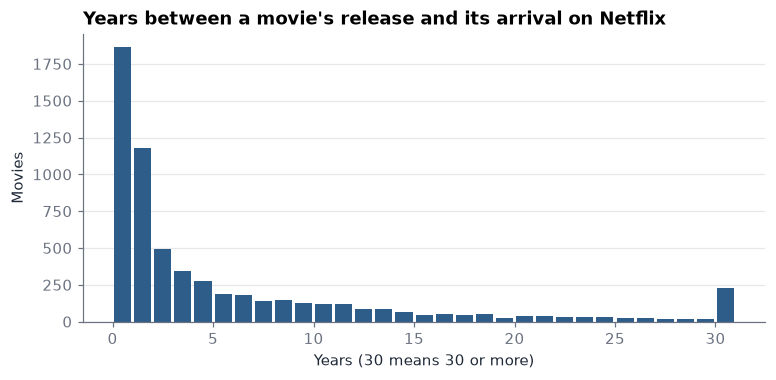

In [9]:
movies = titles[titles["type"] == "Movie"]
lag = movies["years_to_netflix"].dropna().clip(upper=30)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(lag, bins=range(0, 32), color=MOVIE, rwidth=0.85)
ax.set_title("Years between a movie's release and its arrival on Netflix")
ax.set_xlabel("Years (30 means 30 or more)")
ax.set_ylabel("Movies")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
save(fig, "years_to_netflix.png")
print(f"Median: {movies['years_to_netflix'].median():.0f} years")
print(f"Same year: {(movies['years_to_netflix'] == 0).mean():.1%}")
print(f"10+ years: {(movies['years_to_netflix'] >= 10).mean():.1%}")

## Length

A typical movie runs 98 minutes, and half run between 87 and 114. Two thirds of TV shows (67%) have only one season, which fits a catalog adding many new and limited series.

Movie median 98 min, middle half 87-114 min
TV shows with one season: 67.0%


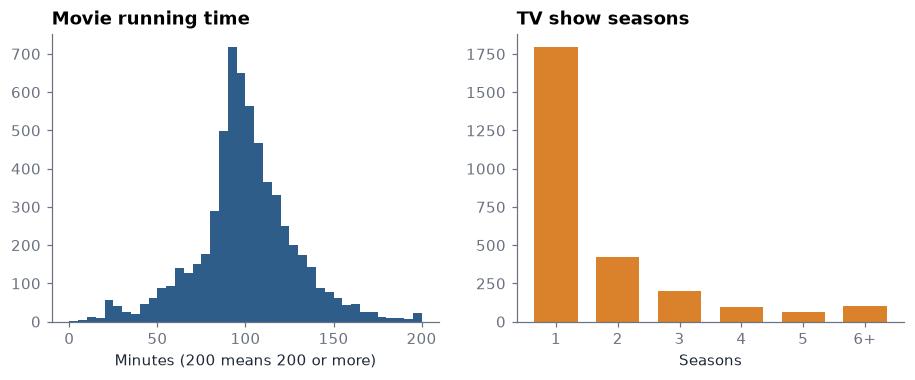

In [10]:
tv = titles[titles["type"] == "TV Show"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.hist(movies["duration_min"].dropna().clip(upper=200), bins=range(0, 205, 5), color=MOVIE)
ax1.set_title("Movie running time")
ax1.set_xlabel("Minutes (200 means 200 or more)")
seasons = tv["seasons"].clip(upper=6).value_counts().sort_index()
ax2.bar(seasons.index.astype(int), seasons.values, color=TV, width=0.7)
ax2.set_xticks(range(1, 7), ["1", "2", "3", "4", "5", "6+"])
ax2.set_title("TV show seasons")
ax2.set_xlabel("Seasons")
save(fig, "duration.png")
print(f"Movie median {movies['duration_min'].median():.0f} min, middle half "
      f"{movies['duration_min'].quantile(0.25):.0f}-{movies['duration_min'].quantile(0.75):.0f} min")
print(f"TV shows with one season: {(tv['seasons'] == 1).mean():.1%}")

## Summary

- **Volume:** 8,807 titles, 70% movies. Additions grew almost fivefold from 2016 to the 2019 peak of 2,016 titles.
- **Recency:** 64% of titles were released in 2016 or later. Half of movies reach Netflix within two years of release.
- **Origin:** the US is involved in 46% of titles with a known country, and India is second with 1,046 titles.
- **Audience:** adult-rated content is the largest group. Kids' content is a much bigger share of TV (17%) than of movies (7%).
- **Format:** two thirds of TV shows have a single season.

**Limits.** This is a snapshot of the catalog as scraped in September 2021, so it shows titles that were available, not everything Netflix ever carried. There is also no viewing data, so nothing here says what people actually watch.